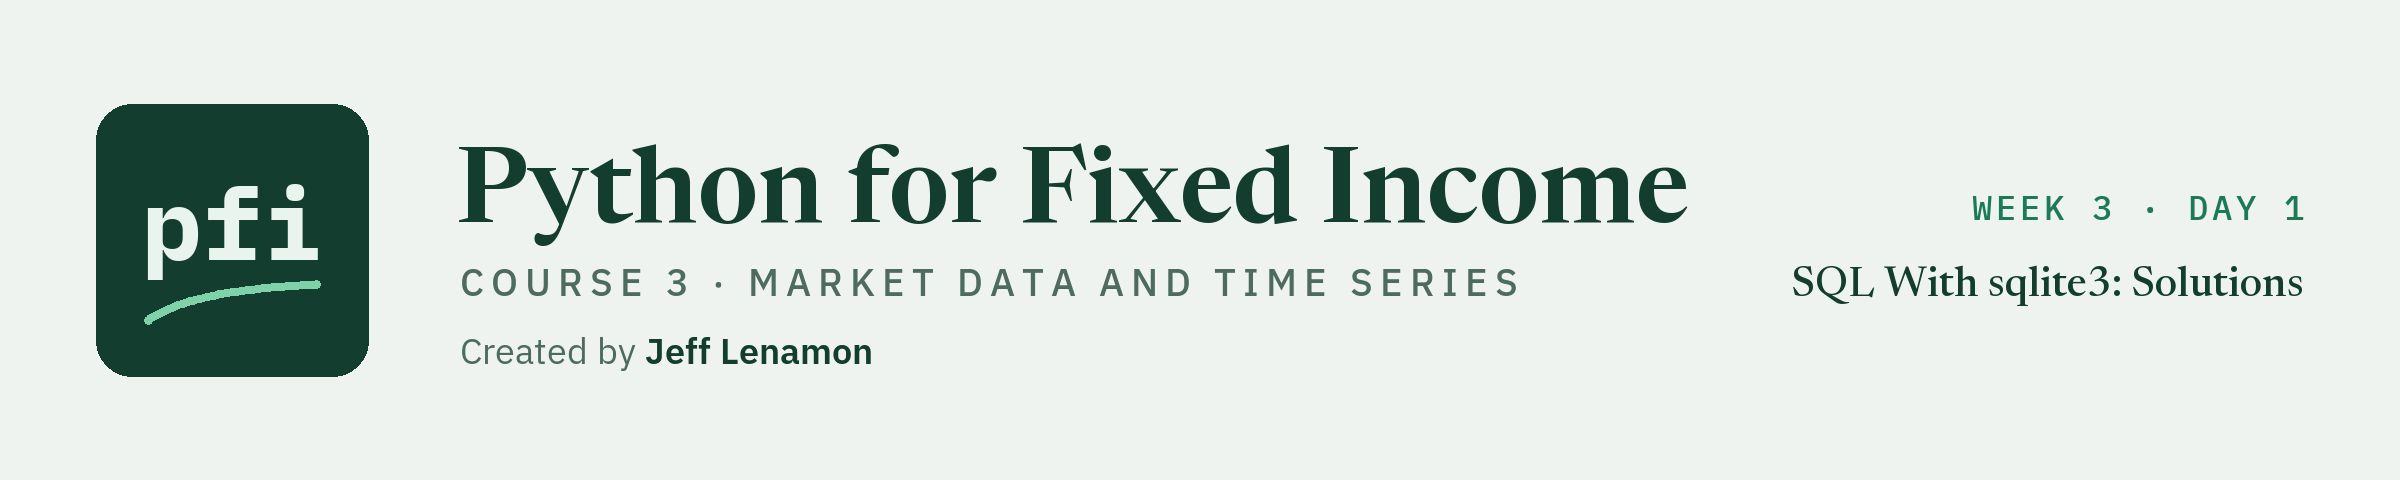

# SQL With sqlite3: Solutions

Week 3, Day 1. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week3/day1/11_sql_with_sqlite3_solutions.ipynb)

## Exercises

Run the next cells first: the work folder, with the module and tests as this notebook leaves them, the imports, the book in `course3.db`, and `check`.

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}course03_market_data/start_of_day/start_day.py
from start_day import start_day

# a new work folder: the data files, Course 2's bondmath.py, and marketdata.py and its tests
# as notebook 11 ends.
# To start the day again, restart the kernel and run all cells.
work = start_day(11, after=11)

Work folder pfi_course3_11_k4w7q2xr: 10 data files, Course 2's bondmath.py, marketdata.py as notebook 11 left it, 11 commits, tagged week1 and week2


In [2]:
import importlib

import pandas as pd

import bondmath
import marketdata as md

holdings = pd.read_csv('holdings.csv')
ratings = pd.read_csv('ratings.csv')
db_path = work / 'course3.db'
md.load_tables(db_path, {'holdings': 'holdings.csv', 'ratings': 'ratings.csv'})

{'holdings': 200, 'ratings': 18}

In [3]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

### Exercise 1

In [4]:
# face held in dollars by bucket, the bucket from ratings
sql = '''SELECT bucket, SUM(par_held) AS face
         FROM holdings
         JOIN ratings ON holdings.rating = ratings.rating
         GROUP BY bucket'''
ex1_sql = md.run_query(db_path, sql)
graded = pd.merge(holdings, ratings, on='rating')
ex1_pandas = graded.groupby('bucket').agg(face=('par_held', 'sum')).reset_index()
md.assert_same_rows(ex1_sql, ex1_pandas, sort_by=['bucket'])
ex1_bbb_face = ex1_sql.loc[ex1_sql['bucket'] == 'BBB', 'face'].iloc[0]
print(f'BBB face held: {ex1_bbb_face:,} dollars')

BBB face held: 151,750,000 dollars


In [5]:
check('Exercise 1 BBB face', ex1_bbb_face, 151750000)

Exercise 1 BBB face: correct


Seven buckets; BBB holds the most face.
Its market value, from the same rows, is 151,163,415.00 dollars.

### Exercise 2

In [6]:
# OAS falling; where two tie, cusip rising
sql = 'SELECT cusip, issuer, oas FROM holdings ORDER BY oas DESC, cusip LIMIT ?'
ex2_sql = md.run_query(db_path, sql, (10,))
# pandas: OAS falling, cusip rising where OAS ties, then the first ten
ex2_pandas = holdings.sort_values(['oas', 'cusip'], ascending=[False, True]).head(10)
md.assert_same_rows(ex2_sql, ex2_pandas[['cusip', 'issuer', 'oas']], sort_by=['cusip'])
assert ex2_sql['cusip'].tolist() == ex2_pandas['cusip'].tolist(), 'the order differs'
ex2_cusips = ex2_sql['cusip'].tolist()
ex2_sql

,cusip,issuer,oas
0,99069RAC4,Feskovar Devices,1551
1,99009JAA9,Calderby Retail,1446
2,99038MAE9,Praxiskan Finance,871
3,99066OAB6,Nevostrin Water,720
4,99066OAD2,Nevostrin Water,719
5,99038MAH2,Praxiskan Finance,707
6,99088KAH5,Galvellix Paper,679
7,99069RAD2,Feskovar Devices,614
8,99036KAA3,Xanizal Industrial,547
9,99049XAE2,Bezamyth Machinery,535


In [7]:
check('Exercise 2 the ten widest', ex2_cusips,
      ['99069RAC4', '99009JAA9', '99038MAE9', '99066OAB6', '99066OAD2',
       '99038MAH2', '99088KAH5', '99069RAD2', '99036KAA3', '99049XAE2'])

Exercise 2 the ten widest: correct


`ORDER BY oas DESC, cusip` sorts by cusip only where OAS ties; none of these ten tie today, and the rule holds the cut steady on a day two do.
`.tolist()` turns a column into a plain list, which compares as one True or False.

### Exercise 3

In [8]:
%%writefile -a marketdata.py


def count_by(db_path: Path, table: str, column: str) -> pd.DataFrame:
    """Count the rows of a table for each value of one column, with SQL.

    Units: counts of rows. Convention: one row per distinct value of `column`, sorted by it, with the two
    columns `column` and row_count. A table or column name cannot be a ? parameter, so each name must be a
    plain identifier (letters, digits, underscore) before it is put into the SQL text.
    Raises ValueError for any other name.
    """
    for name in (table, column):
        if not name.isidentifier():
            raise ValueError(f"{name!r} is not a plain table or column name")
    sql = f"SELECT {column}, COUNT(*) AS row_count FROM {table} GROUP BY {column} ORDER BY {column}"
    return run_query(db_path, sql)

Appending to marketdata.py


In [9]:
%%writefile -a test_marketdata.py


def test_count_by_matches_pandas(tmp_path):
    db_path = build_database(tmp_path)
    holdings = pd.read_csv(HERE / "holdings.csv")
    expected = holdings.groupby("sector").agg(row_count=("cusip", "count")).reset_index()
    md.assert_same_rows(md.count_by(db_path, "holdings", "sector"), expected, sort_by=["sector"])
    with pytest.raises(ValueError):
        md.count_by(db_path, "holdings", "sector; DROP TABLE holdings")

Appending to test_marketdata.py


In [10]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

...............................................                          [100%]
47 passed in 0.50s



In [11]:
# the file changed, so reload before calling the new function
importlib.reload(md)
by_sector = md.count_by(db_path, 'holdings', 'sector')
ex3_energy = by_sector.loc[by_sector['sector'] == 'Energy', 'row_count'].iloc[0]
check('Exercise 3 Energy bonds', ex3_energy, 17)

Exercise 3 Energy bonds: correct


The names go into the SQL text, the only way a name can, and only after the check; a value would have gone in as a `?`.

### Exercise 4: AI check

The bug: `AVG(oas)` is the simple average, every bond counted once whatever its size, where the docstring asked for the market-value weighted average.
It returned 339.38 bp for High Yield and 99.34 for Investment Grade: believable, close, and wrong.
The fix is 11.7's weighted average.

In [12]:
# written for this course in the style of an AI assistant's answer, now fixed
def weighted_oas_by_grade(db_path):
    """Market-value weighted OAS of the book by grade, in basis points.

    Units: OAS in bp; the weights are market values in dollars. Convention: one row per grade,
    with the columns grade, bonds, and oas_bp, where oas_bp is
    sum(oas x market_value) / sum(market_value) over the grade's bonds,
    the same number bondmath.weighted_average gives.
    """
    # the fix: weight each bond's OAS by its market value, as the docstring says
    sql = '''SELECT grade, COUNT(*) AS bonds, SUM(oas * market_value) / SUM(market_value) AS oas_bp
             FROM holdings
             JOIN ratings ON holdings.rating = ratings.rating
             GROUP BY grade ORDER BY grade'''
    return md.run_query(db_path, sql)

In [13]:
# the test, from the docstring: each grade against bondmath
result = weighted_oas_by_grade(db_path).set_index('grade')
graded = pd.merge(holdings, pd.read_csv('ratings.csv'), on='rating')
for grade, bonds in graded.groupby('grade'):
    query_bp = result.loc[grade, 'oas_bp']
    expected = bondmath.weighted_average(bonds['oas'], bonds['market_value'])
    message = f'{grade}: {query_bp:.4f} bp from the query, {expected:.4f} from bondmath'
    assert abs(query_bp - expected) < 1e-9, message
print('Both grades equal bondmath.weighted_average')

Both grades equal bondmath.weighted_average


In [14]:
ex4_ig = result.loc['Investment Grade', 'oas_bp']
ex4_hy = result.loc['High Yield', 'oas_bp']
check('Exercise 4 Investment Grade', ex4_ig, 98.78627910957701)
check('Exercise 4 High Yield', ex4_hy, 334.7313192734511)

Exercise 4 Investment Grade: correct
Exercise 4 High Yield: correct


98.79 bp on 128 Investment Grade bonds and 334.73 on 72 High Yield, the same as `bondmath.weighted_average`.
In Excel, with each bond's grade in column H from `=XLOOKUP(D2,ratings!$A$2:$A$19,ratings!$D$2:$D$19)`, `=SUMPRODUCT(($H$2:$H$201="Investment Grade")*$E$2:$E$201*$F$2:$F$201)/SUMIFS($F$2:$F$201,$H$2:$H$201,"Investment Grade")` returns 98.78627910957701, and `AVERAGEIFS` by grade returns the bug's 99.3359375 and 339.375.
Keep the test: in your test file, it stops an `AVG` slipping back in.